## 1. Титульный лист
# Ансамблевые методы: прогнозирование оттока клиентов
**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 3:** Ансамблевые методы (базовый и продвинутый уровень)  
**Выполнил:** Федорушкин Станислав  
**Группа:** ПКТб-23-1  
**Датасет:** Telco Customer Churn  
**Дата выполнения:** 27.10.2026  
**Репозиторий:** https://github.com/Ogn1k/ml-course-fedorushkin  
**Путь:** `module-3-churn/notebook.ipynb`

Работа подготовлена с помощью OpenAI Codex: изучение материалов, код и оформление.
Метрики и графики получены выполнением кода. Публикация на GitHub — отдельный этап.

## 2. Введение
Решается задача бинарной классификации: по характеристикам клиента оценить риск его ухода.
Раннее выявление риска позволяет предложить поддержку и проверить эффективность программы удержания.
Ансамбль объединяет решения нескольких моделей. Разнообразие ошибок помогает усреднению,
а последовательное исправление ошибок позволяет строить более сложные зависимости.
Поэтому ансамбли уместны для табличных данных со смешанными признаками.

Цели: обучить Random Forest, XGBoost, LightGBM и CatBoost; оптимизировать LightGBM
через 30 испытаний Optuna с пятифолдовой CV; объяснить прогнозы с помощью SHAP.
Основная метрика — ROC-AUC: оценивает ранжирование без привязки к порогу.
Дополнительно нужны Precision, Recall, F1 и PR-AUC: пропустить уходящего клиента
и потратить бюджет на остающегося клиента — разные ошибки.
Accuracy большинства составляет около 73.5%, поэтому одной Accuracy недостаточно.

Holdout 20% изолирован до обучения предобработки. Все настройки выбираются по train/CV.
EDA и бизнес-гипотезы строятся по train; тест не используется для выбора признаков или параметров.

## 3. Теоретическая часть
**Ансамбль.** Несколько базовых моделей объединяются правилом агрегации.
Полезно, чтобы их ошибки не были полностью одинаковыми. Усреднение уменьшает влияние
случайного неудачного дерева. Последовательное обучение добавляет новые компоненты туда,
где текущая композиция ошибается. Рост числа моделей сам по себе не гарантирует улучшение на новых данных.

**Bagging и boosting.** Bagging обучает модели на bootstrap-выборках с возвращением.
Базовые модели можно обучать независимо. Их вероятности усредняются, что обычно снижает дисперсию.
Boosting строит модели последовательно: следующая аппроксимирует направление уменьшения функции потерь.
Он способен снижать смещение, но требует контроля глубины, шага обучения и регуляризации.
Для классификации усреднение относится к вероятностям, а сумма бустинга — к score, преобразуемому в вероятность:
$$H_{bag}(x)=\frac{1}{M}\sum_{i=1}^{M}h_i(x),\qquad
H_{boost}(x)=\sum_{i=1}^{M}\alpha_i h_i(x).$$

**Random Forest.** Это bagging решающих деревьев с дополнительной случайностью при выборе
признаков в узлах. Случайные подмножества снижают корреляцию деревьев. Глубина и минимальное
число объектов в листе контролируют сложность. Веса классов помогают учитывать редкий класс ухода.

**Градиентный бустинг.** Новое дерево приближает отрицательный градиент потерь текущего ансамбля.
XGBoost использует информацию о производных и регуляризацию сложности дерева.
LightGBM использует гистограммы и рост по листьям, поэтому важно ограничивать листья и глубину.
CatBoost предлагает ordered boosting и специальную обработку категорий.
Здесь всем моделям даётся одинаковый Label Encoding по заданию: преимущество нативной
обработки категорий CatBoost отдельно не измеряется. Коды категорий не выражают естественный порядок.

| Модель | Схема | Контроль сложности | Особенность |
|---|---|---|---|
| Random Forest | Bagging | max_depth, min_samples_leaf | Независимые случайные деревья |
| XGBoost | Boosting | max_depth, reg_lambda | Регуляризация, производные потерь |
| LightGBM | Boosting | num_leaves, min_child_samples | Гистограммы, рост по листьям |
| CatBoost | Boosting | depth, l2_leaf_reg | Ordered boosting, нативные категории |

**Stacking.** Разные модели выдают признаки для метамодели. Для её обучения нужны out-of-fold
прогнозы, иначе возникает утечка. Это возможное продолжение работы, в эксперимент не включено.

**Optuna.** Это фреймворк оптимизации гиперпараметров. TPE строит вероятностные модели удачных
и неудачных конфигураций и предлагает перспективные значения. В отличие от сетки поиск
адаптируется к полученным результатам. Здесь оптимизируется средний ROC-AUC пяти CV-фолдов,
а seed и число trials фиксированы; holdout не участвует в objective.

**SHAP.** Вклады признаков основаны на значениях Шепли — распределении результата между участниками.
TreeExplainer вычисляет их для деревьев. Summary показывает направление и распределение вкладов,
bar — средний абсолютный вклад, waterfall объясняет один объект, dependence — связь признака с вкладом.
Для LightGBM объясняется raw score: $f(x)=E[f(X)]+\sum_j\phi_j$,
а $p(x)=1/(1+e^{-f(x)})$. Вклад +0.3 в log-odds не означает +30 процентных пунктов вероятности.
При коррелирующих признаках вклад распределяется неоднозначно; объяснение модели не доказывает причинность.

## 4. Описание данных
Источник задания: [Kaggle Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
CSV получен из [официального репозитория IBM](https://github.com/IBM/telco-customer-churn-on-icp4d/tree/master/data).
Данные учебные; 7043 клиента, 21 столбец: 19 исходных признаков, `customerID` и `Churn`.
Числовые величины — tenure, MonthlyCharges, TotalCharges; SeniorCitizen — бинарная категория.
Прочие признаки описывают демографию, услуги, контракт и оплату.

| Поле | Значение | Обработка |
|---|---|---|
| customerID | Идентификатор | Исключить из признаков |
| tenure | Месяцы обслуживания | Числовой |
| MonthlyCharges | Платёж за месяц | Числовой |
| TotalCharges | Общая сумма, текст | to_numeric; медиана train |
| Contract | Тип контракта | LabelEncoder train |
| Churn | Yes — ушёл, No — остался | Целевая, 1/0 |

Полное описание полей — `data/churn_info.md`; происхождение и SHA-256 — `data/provenance.json`.

In [1]:
# Импорты и фиксированные параметры воспроизводимости.
import os, sys, json, time, hashlib, platform, warnings
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, requests, optuna, shap
from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, RocCurveDisplay)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from churn_pipeline import ChurnPreprocessor, predict_churn, load_remote_model

# Относительные пути: запускать из каталога module-3-churn.
SEED, THREADS = 42, 4
for folder in ['models', 'examples', 'data']:
    Path(folder).mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'font.family': 'DejaVu Sans'})
df = pd.read_csv('data/telco_churn.csv')
print(df.shape)
print(df.head())
# Проверяем именно обязательный набор без дубликатов клиентов.
assert df.shape == (7043, 21) and df.customerID.is_unique
assert df.Churn.value_counts().to_dict() == {'No': 5174, 'Yes': 1869}
display(df.Churn.value_counts().rename('count').to_frame().assign(share=df.Churn.value_counts(normalize=True)))
df.info()
display(df.describe(include='all').T)

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

,count,share
Churn,,
No,5174,0.73463
Yes,1869,0.26537


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


В исходном CSV уходят 1869 клиентов (26.54%), остаются 5174 (73.46%).
Пустые строки в TotalCharges не распознаются обычным isna(); их нужно перевести в NaN.
ID уникален и не несёт переносимой информации для прогноза нового клиента.

## 5. Подготовка данных и EDA
Сначала выполняется стратифицированное разбиение 80/20 с seed=42.
Детальный EDA проводится на train. Пустые TotalCharges заполняются медианой **обучающей** части;
в CV медиана и кодировщики заново обучаются внутри каждого фолда.
Медиана устойчива к большим суммам. Для tenure=0 можно было бы использовать структурный ноль,
но здесь выполняется требование методички; ноль — идея отдельного эксперимента.

Создаются TenureYears, AvgMonthlyCharge, IsNewClient и HasMultipleServices — число подключённых
услуг (0–9, включая интернет). LabelEncoder сохраняется для каждого строкового признака;
неизвестная категория получает -1. SeniorCitizen остаётся 0/1. Масштабирование деревьям
не требуется: scaler сохранён как необязательный артефакт, а модели принимают немасштабированные данные.

Train / test: (5634, 19) (1409, 19) Churn: 0.2653532126375577 0.2654364797728886
Пропуски после to_numeric:


,missing
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


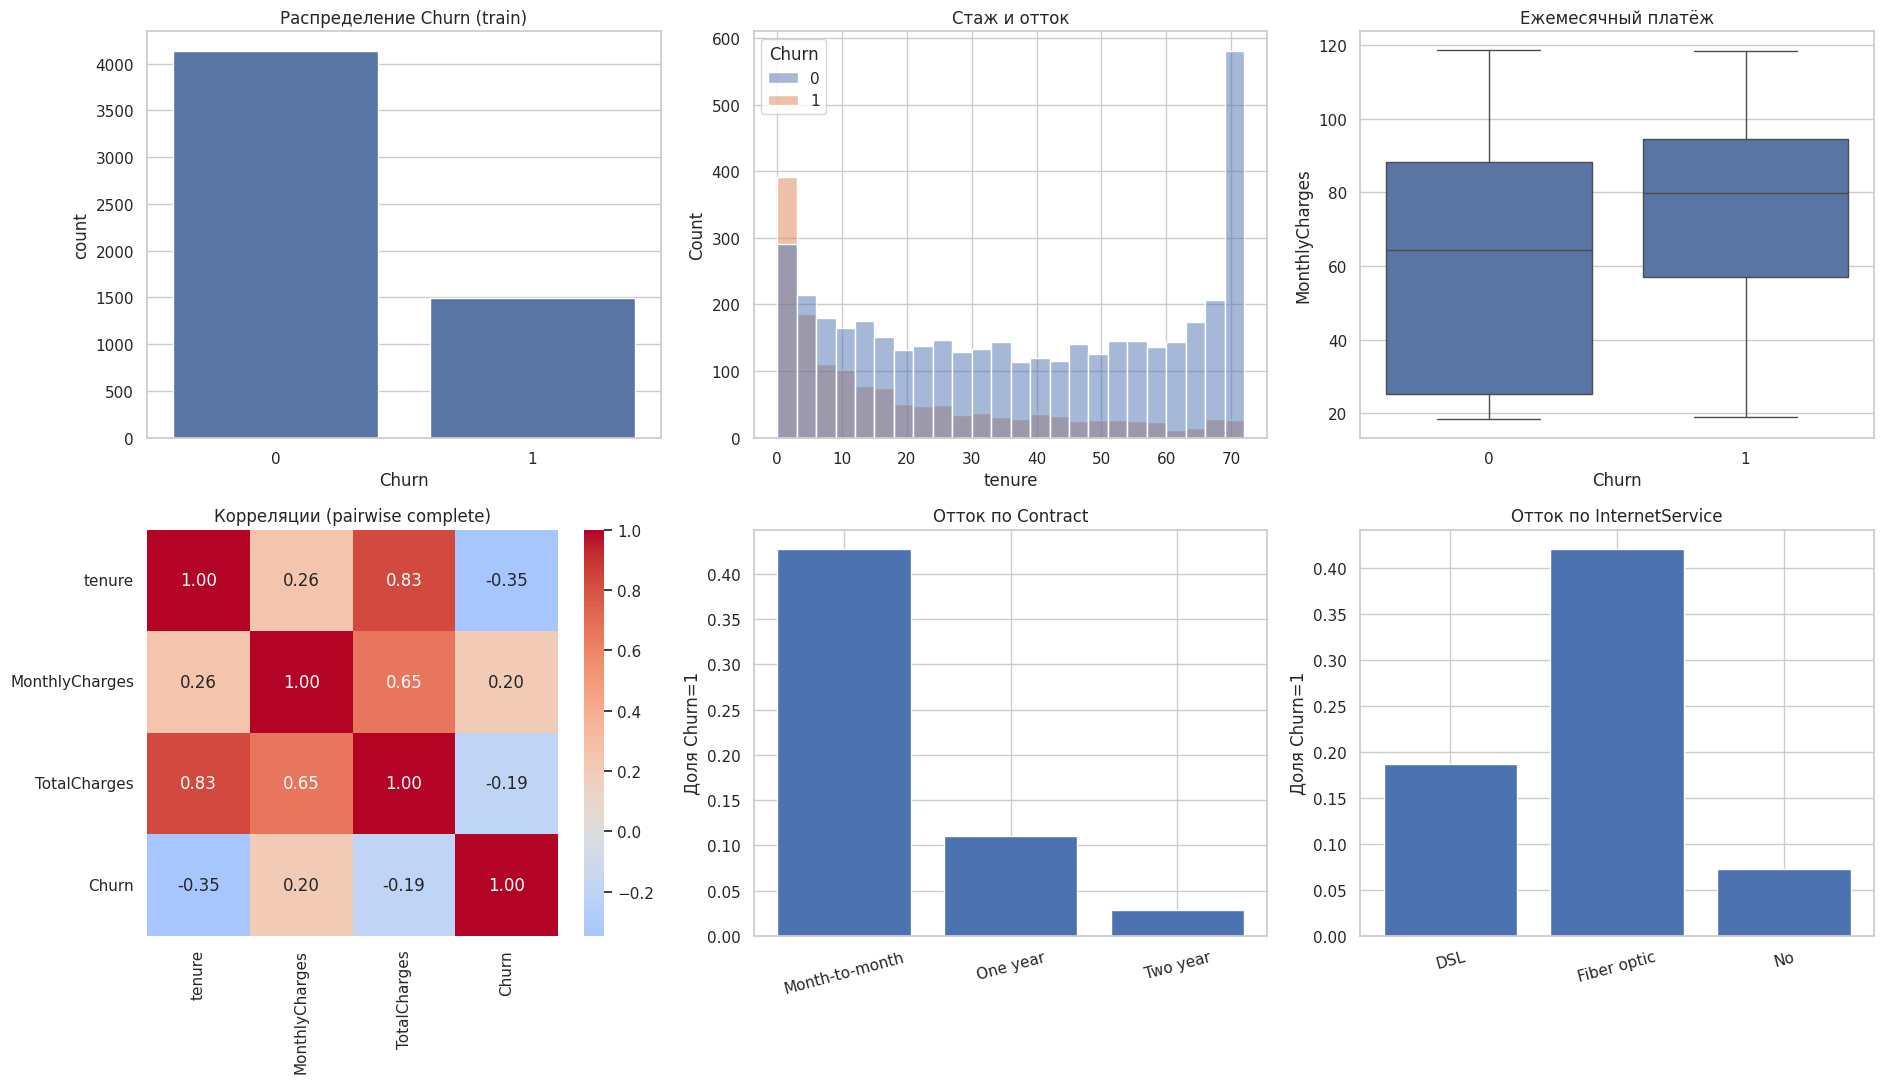

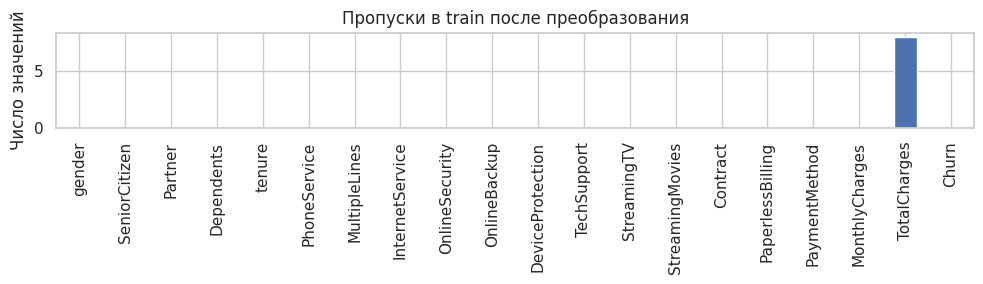

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TenureYears,AvgMonthlyCharge,IsNewClient,HasMultipleServices
3738,1.0,0.0,0.0,0.0,35.0,0.0,1.0,0.0,0.0,0.0,...,2.0,0.0,0.0,2.0,49.20,1701.65,2.916667,47.268056,0.0,4.0
3151,1.0,0.0,1.0,1.0,15.0,1.0,0.0,1.0,2.0,0.0,...,0.0,0.0,0.0,3.0,75.10,1151.55,1.250000,71.971875,0.0,3.0
4860,1.0,0.0,1.0,1.0,13.0,0.0,1.0,0.0,2.0,2.0,...,0.0,2.0,0.0,3.0,40.55,590.35,1.083333,42.167857,0.0,4.0
3867,0.0,0.0,1.0,0.0,26.0,1.0,0.0,0.0,0.0,2.0,...,2.0,2.0,1.0,1.0,73.50,1905.70,2.166667,70.581481,0.0,6.0
3810,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,44.55,44.55,0.083333,22.275000,1.0,2.0


,mean,size
Contract,,
Month-to-month,0.427466,3102
One year,0.110827,1173
Two year,0.028698,1359


,mean,size
tenure,,
False,0.198029,4464
True,0.522222,1170


In [2]:
# Цель кодируется явно; target и ID не подаются в модели.
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print('Train / test:', X_train.shape, X_test.shape, 'Churn:', y_train.mean(), y_test.mean())
# EDA использует только train, никаких новых решений по тестовым графикам.
eda = X_train.copy()
eda['Churn'] = y_train
eda['TotalCharges'] = pd.to_numeric(eda['TotalCharges'], errors='coerce')
print('Пропуски после to_numeric:')
display(eda.isna().sum().to_frame('missing'))

# Шесть обязательных EDA-панелей: классы, стаж, платежи, корреляции, контракты, интернет.
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
sns.countplot(data=eda, x='Churn', ax=axes[0, 0])
axes[0, 0].set_title('Распределение Churn (train)')
sns.histplot(data=eda, x='tenure', hue='Churn', bins=24, ax=axes[0, 1])
axes[0, 1].set_title('Стаж и отток')
sns.boxplot(data=eda, x='Churn', y='MonthlyCharges', ax=axes[0, 2])
axes[0, 2].set_title('Ежемесячный платёж')
sns.heatmap(eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr(), annot=True, fmt='.2f', ax=axes[1, 0], cmap='coolwarm', center=0)
axes[1, 0].set_title('Корреляции (pairwise complete)')
for axis, column in zip(axes[1, 1:], ['Contract', 'InternetService']):
    # Доли без скрытого усреднения и без случайных bootstrap-интервалов.
    rates = eda.groupby(column)['Churn'].mean()
    axis.bar(rates.index, rates.values)
    axis.set(title=f'Отток по {column}', ylabel='Доля Churn=1')
    axis.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
# Отдельно визуализируем пропуски, включая нулевые значения остальных столбцов.
fig, ax = plt.subplots(figsize=(10, 3))
eda.isna().sum().plot.bar(ax=ax)
ax.set(title='Пропуски в train после преобразования', ylabel='Число значений')
fig.tight_layout()
fig.savefig('examples/missing_values.png')
plt.show()

# Демонстрация преобразований; для CV далее создаются новые экземпляры внутри pipeline.
preview = ChurnPreprocessor().fit(X_train)
display(preview.transform(X_train).head())
assert preview.transform(X_train).shape[1] == 23
display(eda.groupby('Contract')['Churn'].agg(['mean', 'size']))
display(eda.groupby(eda.tenure <= 6)['Churn'].agg(['mean', 'size']))

Месячный контракт и малый стаж связаны с повышенным оттоком; доли и размеры групп выведены выше.
Это наблюдаемые связи, а не эффект перевода клиента на другой контракт. TotalCharges тесно
связан со стажем; TenureYears дублирует tenure, поэтому важности могут делиться между ними.
Использованы все признаки из задания, без отбора по holdout.

## 6. Построение и обучение моделей
Четыре baseline используют по 200 деревьев/итераций и веса классов.
Random Forest — устойчивый bagging; XGBoost — регуляризованный бустинг;
LightGBM — эффективный рост деревьев по листьям; CatBoost — альтернативный алгоритм бустинга.
Для единых условий все получают одинаковые 23 Label Encoded признака.
При XGBoost отношение весов вычисляется по y текущего обучающего набора.
Время финального fit включает предобработку, CV измеряется отдельно; используется 4 CPU-потока.

Для всех моделей рассчитывается пятифолдовая CV ROC-AUC, затем fit на всём train.
LightGBM выбран для Optuna **заранее по протоколу задания**, а не по holdout.
После Optuna решение между baseline LightGBM и tuned LightGBM принимается только по CV.

In [3]:
# Фолды одинаковы у всех baseline; каждый fold получает собственную предобработку.
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
ratio = float((y_train == 0).sum() / (y_train == 1).sum())
estimators = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=SEED, n_jobs=THREADS),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=.1, subsample=.9, colsample_bytree=.9, scale_pos_weight=ratio, random_state=SEED, eval_metric='logloss', n_jobs=THREADS),
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=.05, class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=THREADS),
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=.1, auto_class_weights='Balanced', random_seed=SEED, verbose=False, thread_count=THREADS, allow_writing_files=False),
}
models, cv_stats, fit_times = {}, {}, {}
for name, estimator in estimators.items():
    # Pipeline исключает утечку медианы и кодировщиков между CV-фолдами.
    pipeline = Pipeline([('preprocess', ChurnPreprocessor()), ('model', estimator)])
    started = time.perf_counter()
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    cv_stats[name] = {'mean': float(scores.mean()), 'std': float(scores.std()), 'folds': scores.tolist(), 'seconds': time.perf_counter() - started}
    started = time.perf_counter()
    models[name] = pipeline.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - started
    print(name, 'CV:', round(scores.mean(), 5), '+/-', round(scores.std(), 5), 'fit, s:', round(fit_times[name], 3))
# Здесь лучшая baseline определяется по CV, до отображения любых тестовых метрик.
baseline_cv_winner = max(cv_stats, key=lambda n: cv_stats[n]['mean'])
print('Лучшая baseline по CV:', baseline_cv_winner)

Random Forest CV: 0.84303 +/- 0.00984 fit, s: 0.735


XGBoost CV: 0.83402 +/- 0.00808 fit, s: 0.355


LightGBM CV: 0.84055 +/- 0.00901 fit, s: 0.254


CatBoost CV: 0.83777 +/- 0.00929 fit, s: 0.946
Лучшая baseline по CV: Random Forest


Стандартное отклонение фолдов показывает вариативность оценки, а не доверительный интервал.
CV XGBoost использует фиксированный вес от всего train (без holdout); при стратификации
отличие пропорций отдельных фолдов мало. Здесь нет отдельной невзвешенной абляции,
поэтому эффект весов классов сам по себе не оценивается.

## 7. Оценка качества
Считаются Accuracy, Precision, Recall, F1, ROC-AUC и PR-AUC (average precision).
Порог 0.5 фиксирован заранее. Матрица ошибок относится к baseline, выбранной по CV;
ROC-кривые показывают все четыре модели. Результаты holdout не используются в следующем поиске.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV ROC-AUC,Fit seconds
Model,,,,,,,,
Random Forest,0.77360,0.55914,0.69519,0.61979,0.83887,0.64754,0.84303,0.73462
XGBoost,0.77147,0.55462,0.70588,0.62118,0.83177,0.64084,0.83402,0.35531
LightGBM,0.75727,0.53053,0.74332,0.61915,0.83661,0.64284,0.84055,0.25432
CatBoost,0.75444,0.52632,0.74866,0.61810,0.83779,0.64791,0.83777,0.94569


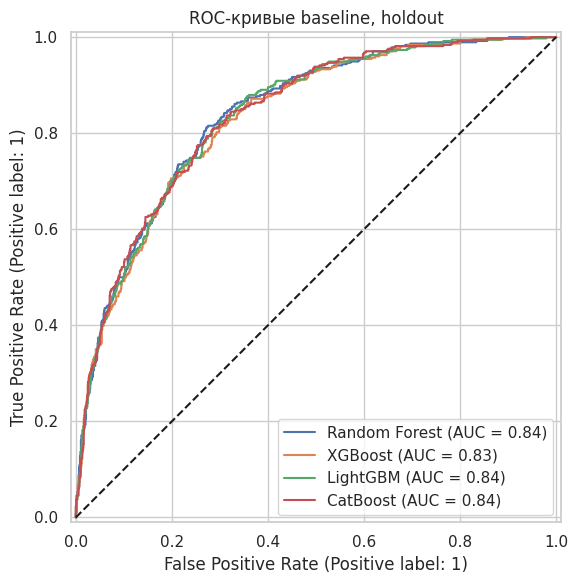

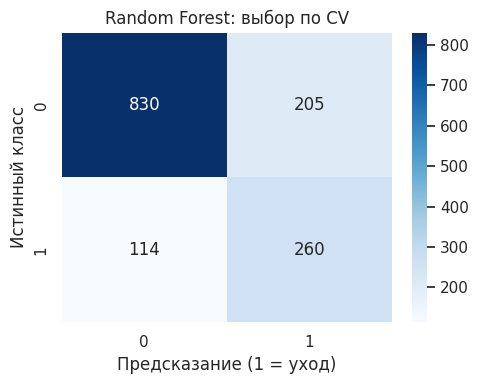

Лучшая baseline по CV — **Random Forest**. Её holdout ROC-AUC = **0.8389**. Самый быстрый финальный fit: **LightGBM**. При пороге 0.5 оцениваем компромисс Precision/Recall по таблице.

In [4]:
# Единая функция метрик; нулевой precision/recall обрабатывается явно.
def evaluate(model, name):
    probability = model.predict_proba(X_test)[:, 1]
    prediction = (probability >= .5).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, prediction),
        'Precision': precision_score(y_test, prediction, zero_division=0),
        'Recall': recall_score(y_test, prediction, zero_division=0),
        'F1': f1_score(y_test, prediction, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probability),
        'PR-AUC': average_precision_score(y_test, probability)}
results = pd.DataFrame([evaluate(model, name) for name, model in models.items()]).set_index('Model')
results['CV ROC-AUC'] = pd.Series({n: v['mean'] for n, v in cv_stats.items()})
results['Fit seconds'] = pd.Series(fit_times)
display(results.round(5))

# ROC и confusion matrix сохраняются также отдельными PNG для сдачи.
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC-кривые baseline, holdout')
fig.tight_layout()
fig.savefig('examples/roc_curves.png')
plt.show()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, models[baseline_cv_winner].predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set(title=f'{baseline_cv_winner}: выбор по CV', xlabel='Предсказание (1 = уход)', ylabel='Истинный класс')
fig.tight_layout()
fig.savefig('examples/confusion_matrix_baseline.png')
plt.show()
# Динамический комментарий опирается на измеренные результаты, а не на ожидаемые цифры.
display(Markdown(f"Лучшая baseline по CV — **{baseline_cv_winner}**. Её holdout ROC-AUC = **{results.loc[baseline_cv_winner, 'ROC-AUC']:.4f}**. "
    f"Самый быстрый финальный fit: **{min(fit_times, key=fit_times.get)}**. При пороге 0.5 оцениваем компромисс Precision/Recall по таблице."))

Тест — один случайный стратифицированный holdout, а не оценка будущего квартала.
Веса классов меняют функцию потерь: predict_proba здесь следует трактовать как score риска,
пока калибровка вероятностей не проверена. Денежный эффект без стоимости контакта,
ценности клиента и эффекта удержания не рассчитывается.

## 8. Интерпретация и бизнес-инсайты
Сравним impurity importance Random Forest и split importance LightGBM.
Шкалы разных алгоритмов нельзя сравнивать напрямую: смотрим отдельные рейтинги.
Важность не задаёт направление влияния и может быть смещена в пользу непрерывных признаков.

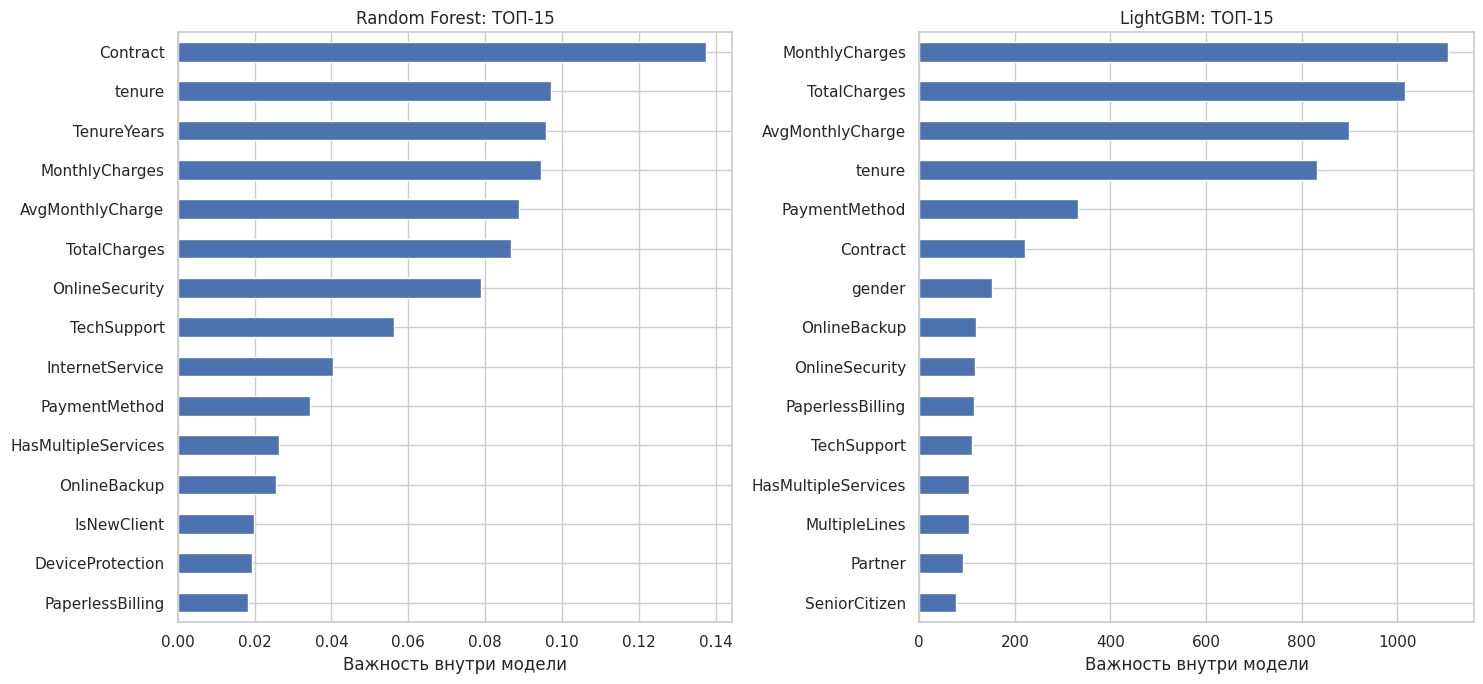

,churn_rate,n
Contract,,
Month-to-month,0.427466,3102
One year,0.110827,1173
Two year,0.028698,1359


,churn_rate,n
InternetService,,
DSL,0.186887,1937
Fiber optic,0.420862,2483
No,0.072488,1214


,churn_rate,n
OnlineSecurity,,
No,0.419378,2797
No internet service,0.072488,1214
Yes,0.144177,1623


,churn_rate,n
TechSupport,,
No,0.417539,2771
No internet service,0.072488,1214
Yes,0.151607,1649


In [5]:
# Имена преобразованных признаков одинаковы для обеих моделей.
feature_cols = models['LightGBM'].named_steps['preprocess'].get_feature_names_out().tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for axis, name in zip(axes, ['Random Forest', 'LightGBM']):
    importance = pd.Series(models[name].named_steps['model'].feature_importances_, index=feature_cols).sort_values()
    importance.tail(15).plot.barh(ax=axis)
    axis.set(title=f'{name}: ТОП-15', xlabel='Важность внутри модели')
    importance.sort_values(ascending=False).to_csv(f'examples/{name.lower().replace(" ", "_")}_importance.csv')
fig.tight_layout()
fig.savefig('examples/feature_importance.png')
plt.show()
# Бизнес-таблицы используют только train; показываем также размеры групп.
for column in ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport']:
    display(eda.groupby(column)['Churn'].agg(['mean', 'size']).rename(columns={'mean': 'churn_rate', 'size': 'n'}))

Гипотезы для бизнеса: проверить онбординг новых клиентов; предложить помощь клиентам
месячных контрактов; изучить причины жалоб клиентов оптоволокна; проверить востребованность
технической поддержки. Эти группы различаются и по другим характеристикам: наличие услуги
не доказывает, что её подключение уменьшит отток. Эффект удержания нужно проверять A/B-тестом.
Значения «No internet service» нельзя трактовать как отказ от конкретной дополнительной услуги.

## 9. Тюнинг гиперпараметров (Optuna)
Выполняются **30 trials**, sampler TPE с seed=42, целевая метрика — пятифолдовый train ROC-AUC.
Оптимизируется LightGBM согласно специальному разделу задания, независимо от результатов holdout.
Диапазоны ограничивают сложность и включают регуляризацию; subsample_freq=1 включает bagging.
Финальная модель выбирается между tuned и baseline LightGBM по CV; тест не входит в objective.
CV после поиска является оптимистичной оценкой выбора: независимая проверка — holdout.

Best CV ROC-AUC: 0.8491207174819453 Search seconds: 43.53132279985584
{
  "max_depth": 5,
  "num_leaves": 13,
  "n_estimators": 400,
  "learning_rate": 0.011641158010924992,
  "subsample": 0.9187614607289891,
  "colsample_bytree": 0.6450868869159563,
  "min_child_samples": 65,
  "reg_alpha": 0.008971128566104576,
  "reg_lambda": 0.003149647174695518
}


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV ROC-AUC,Fit seconds
Model,,,,,,,,
Random Forest,0.77360,0.55914,0.69519,0.61979,0.83887,0.64754,0.84303,0.73462
XGBoost,0.77147,0.55462,0.70588,0.62118,0.83177,0.64084,0.83402,0.35531
LightGBM,0.75727,0.53053,0.74332,0.61915,0.83661,0.64284,0.84055,0.25432
CatBoost,0.75444,0.52632,0.74866,0.61810,0.83779,0.64791,0.83777,0.94569
LightGBM (Optuna),0.75444,0.52448,0.80214,0.63425,0.84787,0.66202,0.84912,0.31342


Выбран **LightGBM (Optuna)**. Изменение holdout ROC-AUC относительно baseline LightGBM: **+0.0113** (абсолютная разница; улучшение не гарантировано и статистическая значимость не проверена).

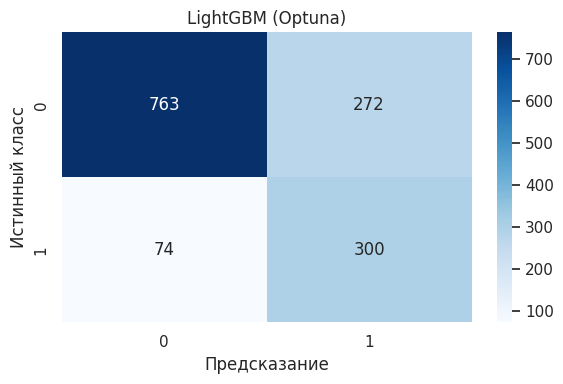

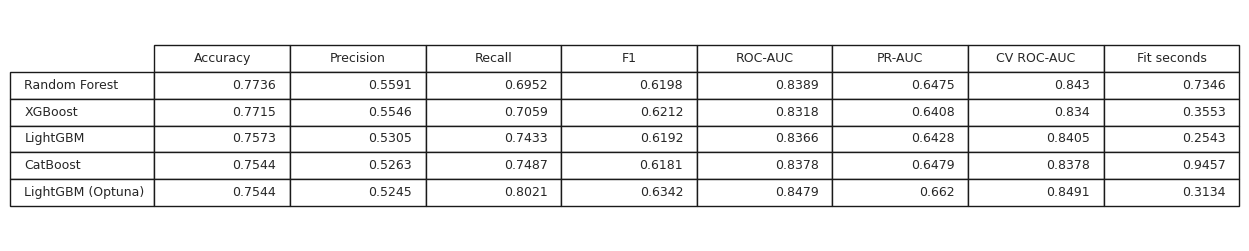

In [6]:
# Убираем подробный лог каждой попытки из отчёта; история сохраняется в CSV.
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    # Число листьев ограничиваем глубиной, исключая бессмысленные комбинации.
    depth = trial.suggest_int('max_depth', 3, 9)
    params = {'max_depth': depth, 'num_leaves': trial.suggest_int('num_leaves', 7, min(63, 2**depth)),
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'learning_rate': trial.suggest_float('learning_rate', .01, .2, log=True),
        'subsample': trial.suggest_float('subsample', .6, 1.),
        'colsample_bytree': trial.suggest_float('colsample_bytree', .6, 1.),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 80),
        'reg_alpha': trial.suggest_float('reg_alpha', .001, 10., log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', .001, 10., log=True)}
    estimator = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=THREADS)
    pipeline = Pipeline([('preprocess', ChurnPreprocessor()), ('model', estimator)])
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    trial.set_user_attr('fold_scores', scores.tolist())
    return float(scores.mean())

# Последовательный поиск воспроизводит порядок предложений TPE.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
search_start = time.perf_counter()
study.optimize(objective, n_trials=30, n_jobs=1)
search_seconds = time.perf_counter() - search_start
study.trials_dataframe().to_csv('examples/optuna_trials.csv', index=False)
print('Best CV ROC-AUC:', study.best_value, 'Search seconds:', search_seconds)
print(json.dumps(study.best_params, indent=2))

# Переобучаем победителя поиска на train, без использования holdout.
tuned_model = Pipeline([('preprocess', ChurnPreprocessor()), ('model', LGBMClassifier(
    **study.best_params, subsample_freq=1, class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=THREADS))])
started = time.perf_counter()
tuned_model.fit(X_train, y_train)
fit_times['LightGBM (Optuna)'] = time.perf_counter() - started
cv_stats['LightGBM (Optuna)'] = {'mean': study.best_value, 'std': float(np.std(study.best_trial.user_attrs['fold_scores'])), 'folds': study.best_trial.user_attrs['fold_scores']}
# Правило выбора зафиксировано заранее: максимум CV среди двух LightGBM.
best_name = 'LightGBM (Optuna)' if study.best_value > cv_stats['LightGBM']['mean'] else 'LightGBM'
best_model = tuned_model if best_name == 'LightGBM (Optuna)' else models['LightGBM']
models['LightGBM (Optuna)'] = tuned_model
results.loc['LightGBM (Optuna)'] = {**evaluate(tuned_model, 'LightGBM (Optuna)'), 'CV ROC-AUC': study.best_value, 'Fit seconds': fit_times['LightGBM (Optuna)']}
display(results.round(5))
gain = results.loc['LightGBM (Optuna)', 'ROC-AUC'] - results.loc['LightGBM', 'ROC-AUC']
display(Markdown(f"Выбран **{best_name}**. Изменение holdout ROC-AUC относительно baseline LightGBM: **{gain:+.4f}** "
    "(абсолютная разница; улучшение не гарантировано и статистическая значимость не проверена)."))

# Полный набор метрик и confusion matrix финальной модели.
results.to_csv('examples/metrics.csv')
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, best_model.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set(title=best_name, xlabel='Предсказание', ylabel='Истинный класс')
fig.tight_layout()
fig.savefig('examples/confusion_matrix.png')
plt.show()
# Таблица метрик в PNG — готовый скриншот для преподавателя.
fig, ax = plt.subplots(figsize=(14, 3))
ax.axis('off')
table = ax.table(cellText=results.round(4).values, rowLabels=results.index, colLabels=results.columns, loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
fig.savefig('examples/metrics.png', bbox_inches='tight', dpi=160)
plt.show()

Оптимизация показывает фактическое изменение, включая возможность ухудшения на тесте.
Тридцать trials не перебирают всё пространство. Повторные эксперименты на том же holdout
потребуют нового независимого теста; здесь протокол зафиксирован до поиска.

## 10. Интерпретация через SHAP
Объясняем выбранную LightGBM. Значения рассчитываются для **всего holdout** на преобразованных
признаках, в единицах raw score (log-odds). Проверяем аддитивность и соответствие sigmoid(score)
выходу predict_proba. Waterfall относится к клиенту с максимальным score ухода на holdout.

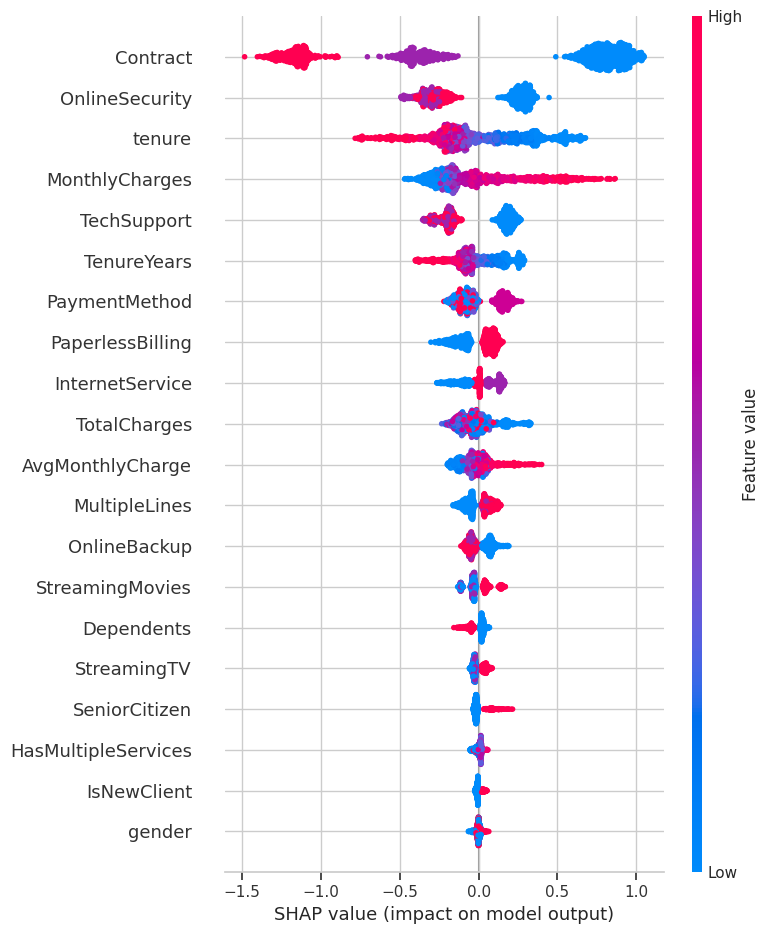

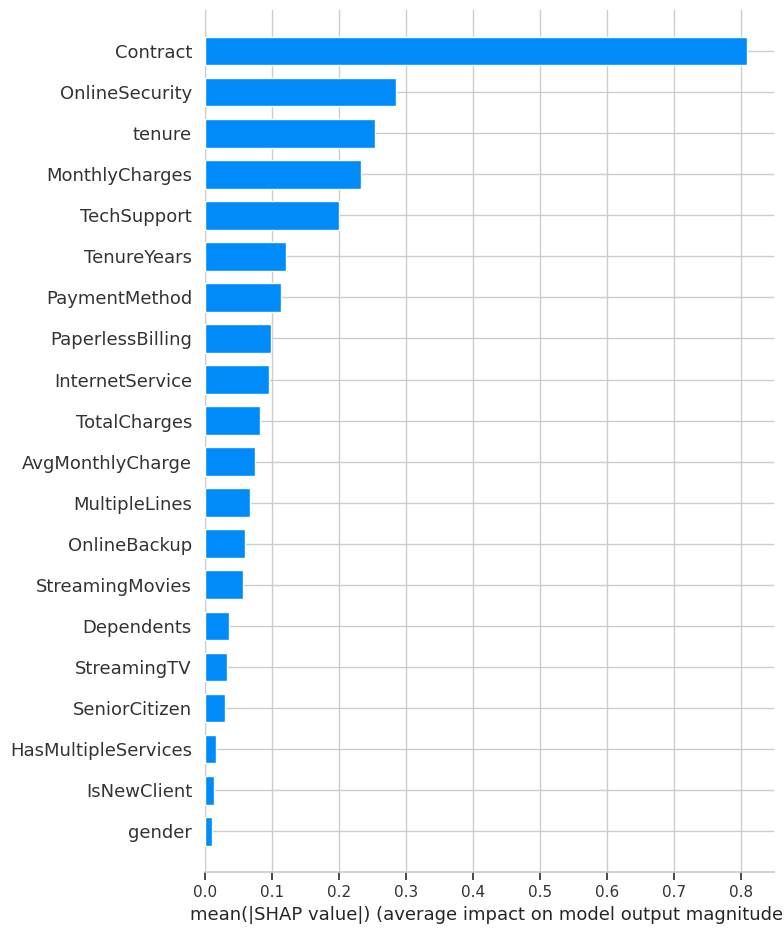

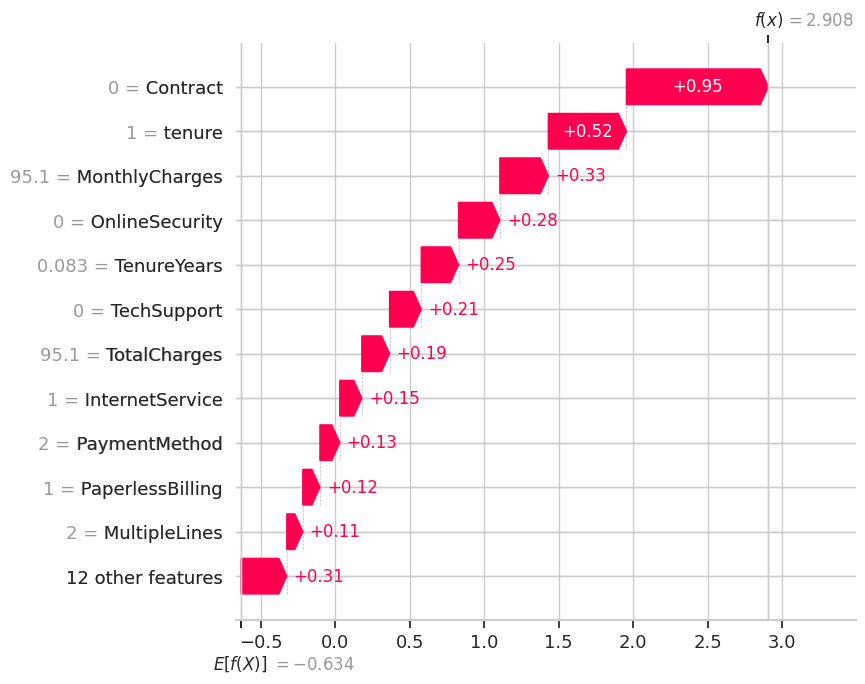

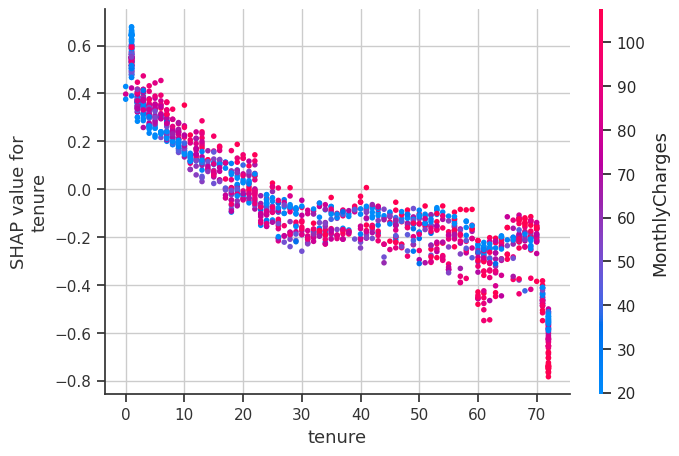

,mean_abs_SHAP_log_odds
Contract,0.808092
OnlineSecurity,0.284530
tenure,0.253415
MonthlyCharges,0.232801
TechSupport,0.200184
TenureYears,0.120622
PaymentMethod,0.113202
PaperlessBilling,0.098307
InternetService,0.094448
TotalCharges,0.081766


,feature,encoded_value,SHAP_log_odds
14,Contract,0.000000,0.953413
4,tenure,1.000000,0.524280
17,MonthlyCharges,95.100000,0.325828
8,OnlineSecurity,0.000000,0.277475
19,TenureYears,0.083333,0.250537
11,TechSupport,0.000000,0.212817
18,TotalCharges,95.100000,0.186359
7,InternetService,1.000000,0.148222


customerID: 5178-LMXOP
Score: 0.9482308673441716 Base log-odds: -0.6340017444321538


Наибольшие средние абсолютные SHAP-вклады: **Contract, OnlineSecurity, tenure, MonthlyCharges, TechSupport**. В локальной таблице положительный вклад повышает raw score ухода, отрицательный снижает.

In [7]:
# Для TreeExplainer берём estimator из полного pipeline и ровно его входные признаки.
encoded_test = best_model.named_steps['preprocess'].transform(X_test)
tree = best_model.named_steps['model']
explainer = shap.TreeExplainer(tree, model_output='raw')
explanation = explainer(encoded_test)
values = explanation.values
base_values = np.asarray(explanation.base_values)
# Совместимость с API, возвращающим измерение класса.
if values.ndim == 3:
    values = values[:, :, 1]
    base_values = base_values[:, 1]
base_values = np.broadcast_to(base_values, (len(encoded_test),))
raw_score = tree.predict(encoded_test, raw_score=True)
assert np.allclose(base_values + values.sum(axis=1), raw_score, atol=1e-5)
assert np.allclose(expit(raw_score), best_model.predict_proba(X_test)[:, 1], atol=1e-7)

# Summary и bar: глобальная структура вкладов, без причинной интерпретации.
shap.summary_plot(values, encoded_test, show=False)
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()
shap.summary_plot(values, encoded_test, plot_type='bar', show=False)
plt.savefig('examples/shap_bar.png', bbox_inches='tight')
plt.show()
# Локальное объяснение объекта с наибольшим риском; индекс сопоставлен с исходным CSV.
worst_position = int(np.argmax(best_model.predict_proba(X_test)[:, 1]))
local = shap.Explanation(values=values[worst_position], base_values=base_values[worst_position], data=encoded_test.iloc[worst_position].values, feature_names=feature_cols)
shap.plots.waterfall(local, max_display=12, show=False)
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()
# Dependence для tenure понятен в исходных месяцах; дополнительная окраска — платёж.
shap.dependence_plot('tenure', values, encoded_test, interaction_index='MonthlyCharges', show=False)
plt.savefig('examples/shap_dependence.png', bbox_inches='tight')
plt.show()
shap_ranking = pd.Series(np.abs(values).mean(axis=0), index=feature_cols).sort_values(ascending=False)
display(shap_ranking.head(10).to_frame('mean_abs_SHAP_log_odds'))
local_table = pd.DataFrame({'feature': feature_cols, 'encoded_value': encoded_test.iloc[worst_position].values, 'SHAP_log_odds': values[worst_position]})
display(local_table.iloc[np.argsort(-np.abs(values[worst_position]))[:8]])
print('customerID:', df.loc[X_test.index[worst_position], 'customerID'])
print('Score:', best_model.predict_proba(X_test)[worst_position, 1], 'Base log-odds:', base_values[worst_position])
display(Markdown('Наибольшие средние абсолютные SHAP-вклады: **' + ', '.join(shap_ranking.head(5).index) + '**. '
    'В локальной таблице положительный вклад повышает raw score ухода, отрицательный снижает.'))
# Сохраняем числа для независимой проверки SHAP и объяснения на защите.
np.savez_compressed('examples/shap_values.npz', values=values, base_values=base_values, raw_score=raw_score, test_indices=X_test.index.to_numpy())
shap_ranking.to_csv('examples/shap_importance.csv')
local_table.to_csv('examples/shap_local_client.csv', index=False)

Красный цвет summary означает высокое **закодированное** значение; для категорий нужно смотреть
`label_encoders.pkl`, а не трактовать красный как «хорошую услугу». TenureYears и tenure
коррелируют, как и AvgMonthlyCharge с платежами. Их вклады нельзя считать независимыми
причинами. Waterfall показывает поведение взвешенной модели, а не доказанный индивидуальный
эффект скидки или точную откалиброванную вероятность ухода.

## 11. Сохранение модели и метаданных
Сохраняются четыре baseline, tuned LightGBM и best_model как **полные pipeline**.
Внутри каждого есть собственная медиана и кодировщики. Отдельные scaler и LabelEncoder
оставлены для выполнения структуры задания; перед predict pipeline вызывать их не нужно.
Метаданные разделяют CV ROC-AUC и test ROC-AUC, содержат seed, разбиение и версии библиотек.

In [8]:
# Имена файлов соответствуют методичке, артефакты сжаты для GitHub.
file_names = {'Random Forest': 'rf_model.pkl', 'XGBoost': 'xgb_model.pkl',
    'LightGBM': 'lgbm_model.pkl', 'CatBoost': 'cat_model.pkl', 'LightGBM (Optuna)': 'tuned_lgbm_model.pkl'}
for name, file_name in file_names.items():
    joblib.dump(models[name], Path('models') / file_name, compress=3)
joblib.dump(best_model, 'models/best_model.pkl', compress=3)
preprocessor = best_model.named_steps['preprocess']
joblib.dump(preprocessor.encoders_, 'models/label_encoders.pkl')
# Scaler обучается исключительно на train, но в деревьях не используется.
scaler = StandardScaler().fit(preprocessor.transform(X_train))
joblib.dump(scaler, 'models/scaler.pkl')
Path('models/feature_cols.json').write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')

# Записываем происхождение данных, версии и точные индексы разбиения.
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib', 'requests',
    'xgboost', 'lightgbm', 'catboost', 'optuna', 'shap', 'nbformat', 'nbclient', 'ipykernel']
versions = {name: version(name) for name in packages}
Path('requirements.txt').write_text(''.join(f'{name}=={v}\n' for name, v in versions.items()), encoding='utf-8')
data_hash = hashlib.sha256(Path('data/telco_churn.csv').read_bytes()).hexdigest()
metadata = {'date': '2026-10-27', 'student': 'Федорушкин Станислав', 'seed': SEED, 'python': platform.python_version(),
    'versions': versions, 'best_model': best_name, 'selection': 'LightGBM baseline vs tuned: train 5-fold CV ROC-AUC',
    'baseline_cv_winner': baseline_cv_winner, 'threshold': .5, 'score_calibrated': False,
    'train_rows': len(X_train), 'test_rows': len(X_test), 'raw_features': list(X_train.columns),
    'engineered_features': feature_cols, 'data_sha256': data_hash, 'scaler_used_in_model': False,
    'train_indices': X_train.index.tolist(), 'test_indices': X_test.index.tolist(), 'remote_verified': False}
metrics = {'test': results.to_dict(orient='index'), 'cv': cv_stats, 'best_model': best_name,
    'best_test_roc_auc': float(results.loc[best_name, 'ROC-AUC']), 'best_cv_roc_auc': cv_stats[best_name]['mean'],
    'optuna_best_params': study.best_params, 'optuna_trials': len(study.trials), 'search_seconds': search_seconds}
for filename, content in [('metadata.json', metadata), ('metrics.json', metrics)]:
    Path('models', filename).write_text(json.dumps(content, ensure_ascii=False, indent=2), encoding='utf-8')
provenance = {'download_date': '2026-10-27', 'url': 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv',
    'assignment_source': 'https://www.kaggle.com/datasets/blastchar/telco-customer-churn', 'sha256': data_hash,
    'rows': len(df), 'columns': len(df.columns), 'note': 'Original CSV, unchanged bytes; preprocessing is inside pipelines.'}
Path('data/provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
print('Сохранено: модели, предобработка, признаки, метрики, метаданные, версии.')

Сохранено: модели, предобработка, признаки, метрики, метаданные, версии.


Артефакты позволяют предсказывать на исходных строках без ручного восстановления преобразований.
`best_model.pkl` содержит пользовательский класс из `churn_pipeline.py`: этот файл и совместимые
версии библиотек должны быть доступны при загрузке. joblib загружается только из доверенного источника.

## 12. Загрузка модели из репозитория
Сначала проверим локальный round-trip на трёх клиентах: классы и score должны совпадать.
Raw-загрузка выполняется по переменной `CHURN_VERIFY_REMOTE=1` после публикации файлов в main.
До публикации этот этап честно отмечен как **не проверенный**, локальная загрузка не подменяет HTTP.

In [9]:
# Проверяем сериализацию на трёх исходных клиентах.
clients = X_test.iloc[:3]
loaded = joblib.load('models/best_model.pkl')
original_scores = best_model.predict_proba(clients)[:, 1]
loaded_scores = loaded.predict_proba(clients)[:, 1]
assert np.array_equal(best_model.predict(clients), loaded.predict(clients))
assert np.allclose(original_scores, loaded_scores, atol=1e-12)
display(predict_churn(clients, loaded))
print('Локальные классы и score совпадают на трёх клиентах.')

# Для проверки опубликованного репозитория включите переменную окружения и выполните ячейку.
BASE_URL = 'https://raw.githubusercontent.com/Ogn1k/ml-course-fedorushkin/main/module-3-churn'
if os.environ.get('CHURN_VERIFY_REMOTE') == '1':
    remote = load_remote_model(BASE_URL)
    response = requests.get(f'{BASE_URL}/models/feature_cols.json', timeout=60)
    response.raise_for_status()
    assert response.json() == feature_cols
    assert np.array_equal(remote.predict(clients), best_model.predict(clients))
    assert np.allclose(remote.predict_proba(clients), best_model.predict_proba(clients))
    metadata['remote_verified'] = True
    Path('models/metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    print('GitHub raw: классы и score совпадают на трёх клиентах.')
else:
    print('GitHub raw НЕ проверен: сначала опубликуйте модуль, затем включите CHURN_VERIFY_REMOTE=1.')

,churn_score,prediction
0,0.040669,0
1,0.887388,1
2,0.186896,0


Локальные классы и score совпадают на трёх клиентах.


GitHub raw: классы и score совпадают на трёх клиентах.


Для воспроизведения HTTP-проверки загрузите также `churn_pipeline.py` и установите requirements.
Проверка специально завершится ошибкой при HTTP 404 или несовпадении прогнозов: тихой замены
удалённой модели локальной здесь нет. Инструкция публикации приведена в README модуля.

## 13. Выводы
Обучены четыре ансамбля и выполнено 30 испытаний LightGBM с пятифолдовой CV.
Импутация и кодирование обучались внутри фолдов; ID и цель исключены из признаков.
Вычислены метрики, время обучения, важности и четыре вида SHAP-графиков.
Лучшее CV и независимый holdout приведены ниже: выбор LightGBM зафиксирован методичкой,
а выбор baseline/tuned внутри этого семейства выполнен по train CV.

In [10]:
# Итоговые числа берутся из вычисленных таблиц, без ручного копирования метрик.
row = results.loc[best_name]
display(Markdown(f"Итоговая модель: **{best_name}**, CV ROC-AUC **{cv_stats[best_name]['mean']:.4f}**, "
    f"holdout ROC-AUC **{row['ROC-AUC']:.4f}**, F1 **{row['F1']:.4f}**, Recall **{row['Recall']:.4f}**. "
    f"Топ SHAP: {', '.join(shap_ranking.head(5).index)}. Локальная загрузка проверена; "
    f"GitHub raw: {'проверен, прогнозы совпали' if metadata['remote_verified'] else 'не проверен'}."))

Итоговая модель: **LightGBM (Optuna)**, CV ROC-AUC **0.8491**, holdout ROC-AUC **0.8479**, F1 **0.6342**, Recall **0.8021**. Топ SHAP: Contract, OnlineSecurity, tenure, MonthlyCharges, TechSupport. Локальная загрузка проверена; GitHub raw: проверен, прогнозы совпали.

**Трудности.** Дисбаланс учитывается весами классов, но score не откалиброван. В TotalCharges
есть скрытые текстовые пропуски. Label Encoding даёт искусственный порядок категорий, а
коррелирующие исходные и производные признаки затрудняют однозначную интерпретацию важности.
Реальный эффект удержания по этим наблюдательным данным не измеряется.

**Идеи улучшения:** (1) сравнить нативные категории CatBoost и one-hot на одинаковых CV-фолдах;
(2) построить stacking на OOF-прогнозах; (3) проверить SMOTENC внутри train-фолдов, сохранив
дискретность категорий; (4) откалибровать score на отдельной validation/CV;
(5) выбрать порог по стоимости FP/FN на validation; (6) добавить временной тест на новых кварталах;
(7) проверить структурный ноль для TotalCharges при tenure=0 и абляцию дублирующих признаков;
(8) проверить retention-кампанию A/B-тестом с измерением инкрементального эффекта.
Все эти пункты — будущие эксперименты, не заявленные выполненными.

## 14. Список источников + Приложение
1. Учебные материалы «Модуль 3. Ансамблевые методы» (DOCX, PDF, IPYNB, HTML) и практическое
   задание Telco Customer Churn (DOCX, IPYNB), предоставленные преподавателем.
2. [IBM: Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d).
3. [Breiman (2001), Random Forests](https://doi.org/10.1023/A:1010933404324).
4. [Chen & Guestrin (2016), XGBoost](https://arxiv.org/abs/1603.02754).
5. [Ke et al. (2017), LightGBM](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html).
6. [Prokhorenkova et al. (2018), CatBoost](https://arxiv.org/abs/1706.09516).
7. [Lundberg & Lee (2017), SHAP](https://arxiv.org/abs/1705.07874).
8. [Akiba et al. (2019), Optuna](https://arxiv.org/abs/1907.10902).
9. [Scikit-learn: предотвращение утечки](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

**Приложение.** Полный вычислительный код с комментариями содержится в `appendix_full_code.py`,
класс предобработки и инференс — в `churn_pipeline.py`. Ниже приведены их тексты и точные зависимости.

In [11]:
# Отображаем исходники и версии, сохраняя полный код в отчёте.
for filename in ['churn_pipeline.py', 'appendix_full_code.py', 'requirements.txt']:
    source_text = Path(filename).read_text(encoding='utf-8')
    display(Markdown(f'### {filename}\n```python\n{source_text}\n```'))

### churn_pipeline.py
```python
"""Предобработка Telco Churn и загрузка сохранённого полного pipeline."""
from io import BytesIO

import joblib
import numpy as np
import pandas as pd
import requests
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.validation import check_is_fitted


class ChurnPreprocessor(TransformerMixin, BaseEstimator):
    """Fit медианы и LabelEncoder только на train; новые категории получают -1."""

    def _engineer(self, X):
        # ID и целевая переменная никогда не становятся признаками.
        frame = X.drop(columns=['customerID', 'Churn'], errors='ignore').copy()
        frame['TotalCharges'] = pd.to_numeric(frame['TotalCharges'], errors='coerce')
        # Используем медиану из fit; статистики новых клиентов не учитываем.
        frame['TotalCharges'] = frame['TotalCharges'].fillna(self.total_median_)
        frame['TenureYears'] = frame['tenure'] / 12
        frame['AvgMonthlyCharge'] = frame['TotalCharges'] / (frame['tenure'] + 1)
        frame['IsNewClient'] = (frame['tenure'] <= 6).astype(int)
        # Считаем 9 разных услуг: интернет считается один раз.
        services = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
        frame['HasMultipleServices'] = frame[services].eq('Yes').sum(axis=1)
        frame['HasMultipleServices'] += frame['InternetService'].ne('No').astype(int)
        return frame

    def fit(self, X, y=None):
        # Сохраняем схему исходных данных и единственную обучаемую импутацию.
        self.raw_columns_ = [c for c in X if c not in ['customerID', 'Churn']]
        self.total_median_ = float(pd.to_numeric(X['TotalCharges'], errors='coerce').median())
        frame = self._engineer(X)
        # LabelEncoder применяем отдельно к каждому категориальному столбцу.
        self.encoders_ = {c: LabelEncoder().fit(frame[c].fillna('__missing__').astype(str))
                          for c in frame.select_dtypes(include=['object', 'string'])}
        self.feature_names_out_ = list(frame.columns)
        return self

    def transform(self, X):
        check_is_fitted(self, 'encoders_')
        # Проверка схемы предотвращает незаметное предсказание на неполных данных.
        missing = set(self.raw_columns_) - set(X.columns)
        if missing:
            raise ValueError(f'Missing required columns: {sorted(missing)}')
        frame = self._engineer(X[self.raw_columns_])
        for column, encoder in self.encoders_.items():
            # Неизвестные категории обрабатываем без переобучения кодировщика.
            mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
            frame[column] = frame[column].fillna('__missing__').astype(str).map(mapping).fillna(-1)
        return frame[self.feature_names_out_].astype(float)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)


def predict_churn(clients, model, threshold=0.5):
    """Принимает исходные 19 признаков: DataFrame, словарь или список словарей."""
    frame = pd.DataFrame([clients] if isinstance(clients, dict) else clients)
    # Полный pipeline сам выполняет импутацию и кодирование.
    probability = model.predict_proba(frame)[:, 1]
    return pd.DataFrame({'churn_score': probability, 'prediction': (probability >= threshold).astype(int)})


def load_remote_model(base_url):
    """Загружать joblib следует только из доверенного собственного репозитория."""
    response = requests.get(f'{base_url.rstrip("/")}/models/best_model.pkl', timeout=60)
    response.raise_for_status()
    # Модуль churn_pipeline должен быть доступен для десериализации класса.
    return joblib.load(BytesIO(response.content))

```

### appendix_full_code.py
```python
"""Полный код лабораторной №3; запускать из каталога модуля."""


# %%
# Импорты и фиксированные параметры воспроизводимости.
import os, sys, json, time, hashlib, platform, warnings
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, requests, optuna, shap
from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, RocCurveDisplay)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from churn_pipeline import ChurnPreprocessor, predict_churn, load_remote_model

# Относительные пути: запускать из каталога module-3-churn.
SEED, THREADS = 42, 4
for folder in ['models', 'examples', 'data']:
    Path(folder).mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'font.family': 'DejaVu Sans'})
df = pd.read_csv('data/telco_churn.csv')
print(df.shape)
print(df.head())
# Проверяем именно обязательный набор без дубликатов клиентов.
assert df.shape == (7043, 21) and df.customerID.is_unique
assert df.Churn.value_counts().to_dict() == {'No': 5174, 'Yes': 1869}
display(df.Churn.value_counts().rename('count').to_frame().assign(share=df.Churn.value_counts(normalize=True)))
df.info()
display(df.describe(include='all').T)

# %%
# Цель кодируется явно; target и ID не подаются в модели.
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print('Train / test:', X_train.shape, X_test.shape, 'Churn:', y_train.mean(), y_test.mean())
# EDA использует только train, никаких новых решений по тестовым графикам.
eda = X_train.copy()
eda['Churn'] = y_train
eda['TotalCharges'] = pd.to_numeric(eda['TotalCharges'], errors='coerce')
print('Пропуски после to_numeric:')
display(eda.isna().sum().to_frame('missing'))

# Шесть обязательных EDA-панелей: классы, стаж, платежи, корреляции, контракты, интернет.
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
sns.countplot(data=eda, x='Churn', ax=axes[0, 0])
axes[0, 0].set_title('Распределение Churn (train)')
sns.histplot(data=eda, x='tenure', hue='Churn', bins=24, ax=axes[0, 1])
axes[0, 1].set_title('Стаж и отток')
sns.boxplot(data=eda, x='Churn', y='MonthlyCharges', ax=axes[0, 2])
axes[0, 2].set_title('Ежемесячный платёж')
sns.heatmap(eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr(), annot=True, fmt='.2f', ax=axes[1, 0], cmap='coolwarm', center=0)
axes[1, 0].set_title('Корреляции (pairwise complete)')
for axis, column in zip(axes[1, 1:], ['Contract', 'InternetService']):
    # Доли без скрытого усреднения и без случайных bootstrap-интервалов.
    rates = eda.groupby(column)['Churn'].mean()
    axis.bar(rates.index, rates.values)
    axis.set(title=f'Отток по {column}', ylabel='Доля Churn=1')
    axis.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
# Отдельно визуализируем пропуски, включая нулевые значения остальных столбцов.
fig, ax = plt.subplots(figsize=(10, 3))
eda.isna().sum().plot.bar(ax=ax)
ax.set(title='Пропуски в train после преобразования', ylabel='Число значений')
fig.tight_layout()
fig.savefig('examples/missing_values.png')
plt.show()

# Демонстрация преобразований; для CV далее создаются новые экземпляры внутри pipeline.
preview = ChurnPreprocessor().fit(X_train)
display(preview.transform(X_train).head())
assert preview.transform(X_train).shape[1] == 23
display(eda.groupby('Contract')['Churn'].agg(['mean', 'size']))
display(eda.groupby(eda.tenure <= 6)['Churn'].agg(['mean', 'size']))

# %%
# Фолды одинаковы у всех baseline; каждый fold получает собственную предобработку.
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
ratio = float((y_train == 0).sum() / (y_train == 1).sum())
estimators = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=SEED, n_jobs=THREADS),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=.1, subsample=.9, colsample_bytree=.9, scale_pos_weight=ratio, random_state=SEED, eval_metric='logloss', n_jobs=THREADS),
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=.05, class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=THREADS),
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=.1, auto_class_weights='Balanced', random_seed=SEED, verbose=False, thread_count=THREADS, allow_writing_files=False),
}
models, cv_stats, fit_times = {}, {}, {}
for name, estimator in estimators.items():
    # Pipeline исключает утечку медианы и кодировщиков между CV-фолдами.
    pipeline = Pipeline([('preprocess', ChurnPreprocessor()), ('model', estimator)])
    started = time.perf_counter()
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    cv_stats[name] = {'mean': float(scores.mean()), 'std': float(scores.std()), 'folds': scores.tolist(), 'seconds': time.perf_counter() - started}
    started = time.perf_counter()
    models[name] = pipeline.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - started
    print(name, 'CV:', round(scores.mean(), 5), '+/-', round(scores.std(), 5), 'fit, s:', round(fit_times[name], 3))
# Здесь лучшая baseline определяется по CV, до отображения любых тестовых метрик.
baseline_cv_winner = max(cv_stats, key=lambda n: cv_stats[n]['mean'])
print('Лучшая baseline по CV:', baseline_cv_winner)

# %%
# Единая функция метрик; нулевой precision/recall обрабатывается явно.
def evaluate(model, name):
    probability = model.predict_proba(X_test)[:, 1]
    prediction = (probability >= .5).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, prediction),
        'Precision': precision_score(y_test, prediction, zero_division=0),
        'Recall': recall_score(y_test, prediction, zero_division=0),
        'F1': f1_score(y_test, prediction, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probability),
        'PR-AUC': average_precision_score(y_test, probability)}
results = pd.DataFrame([evaluate(model, name) for name, model in models.items()]).set_index('Model')
results['CV ROC-AUC'] = pd.Series({n: v['mean'] for n, v in cv_stats.items()})
results['Fit seconds'] = pd.Series(fit_times)
display(results.round(5))

# ROC и confusion matrix сохраняются также отдельными PNG для сдачи.
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC-кривые baseline, holdout')
fig.tight_layout()
fig.savefig('examples/roc_curves.png')
plt.show()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, models[baseline_cv_winner].predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set(title=f'{baseline_cv_winner}: выбор по CV', xlabel='Предсказание (1 = уход)', ylabel='Истинный класс')
fig.tight_layout()
fig.savefig('examples/confusion_matrix_baseline.png')
plt.show()
# Динамический комментарий опирается на измеренные результаты, а не на ожидаемые цифры.
display(Markdown(f"Лучшая baseline по CV — **{baseline_cv_winner}**. Её holdout ROC-AUC = **{results.loc[baseline_cv_winner, 'ROC-AUC']:.4f}**. "
    f"Самый быстрый финальный fit: **{min(fit_times, key=fit_times.get)}**. При пороге 0.5 оцениваем компромисс Precision/Recall по таблице."))

# %%
# Имена преобразованных признаков одинаковы для обеих моделей.
feature_cols = models['LightGBM'].named_steps['preprocess'].get_feature_names_out().tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for axis, name in zip(axes, ['Random Forest', 'LightGBM']):
    importance = pd.Series(models[name].named_steps['model'].feature_importances_, index=feature_cols).sort_values()
    importance.tail(15).plot.barh(ax=axis)
    axis.set(title=f'{name}: ТОП-15', xlabel='Важность внутри модели')
    importance.sort_values(ascending=False).to_csv(f'examples/{name.lower().replace(" ", "_")}_importance.csv')
fig.tight_layout()
fig.savefig('examples/feature_importance.png')
plt.show()
# Бизнес-таблицы используют только train; показываем также размеры групп.
for column in ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport']:
    display(eda.groupby(column)['Churn'].agg(['mean', 'size']).rename(columns={'mean': 'churn_rate', 'size': 'n'}))

# %%
# Убираем подробный лог каждой попытки из отчёта; история сохраняется в CSV.
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    # Число листьев ограничиваем глубиной, исключая бессмысленные комбинации.
    depth = trial.suggest_int('max_depth', 3, 9)
    params = {'max_depth': depth, 'num_leaves': trial.suggest_int('num_leaves', 7, min(63, 2**depth)),
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'learning_rate': trial.suggest_float('learning_rate', .01, .2, log=True),
        'subsample': trial.suggest_float('subsample', .6, 1.),
        'colsample_bytree': trial.suggest_float('colsample_bytree', .6, 1.),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 80),
        'reg_alpha': trial.suggest_float('reg_alpha', .001, 10., log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', .001, 10., log=True)}
    estimator = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=THREADS)
    pipeline = Pipeline([('preprocess', ChurnPreprocessor()), ('model', estimator)])
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    trial.set_user_attr('fold_scores', scores.tolist())
    return float(scores.mean())

# Последовательный поиск воспроизводит порядок предложений TPE.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
search_start = time.perf_counter()
study.optimize(objective, n_trials=30, n_jobs=1)
search_seconds = time.perf_counter() - search_start
study.trials_dataframe().to_csv('examples/optuna_trials.csv', index=False)
print('Best CV ROC-AUC:', study.best_value, 'Search seconds:', search_seconds)
print(json.dumps(study.best_params, indent=2))

# Переобучаем победителя поиска на train, без использования holdout.
tuned_model = Pipeline([('preprocess', ChurnPreprocessor()), ('model', LGBMClassifier(
    **study.best_params, subsample_freq=1, class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=THREADS))])
started = time.perf_counter()
tuned_model.fit(X_train, y_train)
fit_times['LightGBM (Optuna)'] = time.perf_counter() - started
cv_stats['LightGBM (Optuna)'] = {'mean': study.best_value, 'std': float(np.std(study.best_trial.user_attrs['fold_scores'])), 'folds': study.best_trial.user_attrs['fold_scores']}
# Правило выбора зафиксировано заранее: максимум CV среди двух LightGBM.
best_name = 'LightGBM (Optuna)' if study.best_value > cv_stats['LightGBM']['mean'] else 'LightGBM'
best_model = tuned_model if best_name == 'LightGBM (Optuna)' else models['LightGBM']
models['LightGBM (Optuna)'] = tuned_model
results.loc['LightGBM (Optuna)'] = {**evaluate(tuned_model, 'LightGBM (Optuna)'), 'CV ROC-AUC': study.best_value, 'Fit seconds': fit_times['LightGBM (Optuna)']}
display(results.round(5))
gain = results.loc['LightGBM (Optuna)', 'ROC-AUC'] - results.loc['LightGBM', 'ROC-AUC']
display(Markdown(f"Выбран **{best_name}**. Изменение holdout ROC-AUC относительно baseline LightGBM: **{gain:+.4f}** "
    "(абсолютная разница; улучшение не гарантировано и статистическая значимость не проверена)."))

# Полный набор метрик и confusion matrix финальной модели.
results.to_csv('examples/metrics.csv')
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, best_model.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set(title=best_name, xlabel='Предсказание', ylabel='Истинный класс')
fig.tight_layout()
fig.savefig('examples/confusion_matrix.png')
plt.show()
# Таблица метрик в PNG — готовый скриншот для преподавателя.
fig, ax = plt.subplots(figsize=(14, 3))
ax.axis('off')
table = ax.table(cellText=results.round(4).values, rowLabels=results.index, colLabels=results.columns, loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
fig.savefig('examples/metrics.png', bbox_inches='tight', dpi=160)
plt.show()

# %%
# Для TreeExplainer берём estimator из полного pipeline и ровно его входные признаки.
encoded_test = best_model.named_steps['preprocess'].transform(X_test)
tree = best_model.named_steps['model']
explainer = shap.TreeExplainer(tree, model_output='raw')
explanation = explainer(encoded_test)
values = explanation.values
base_values = np.asarray(explanation.base_values)
# Совместимость с API, возвращающим измерение класса.
if values.ndim == 3:
    values = values[:, :, 1]
    base_values = base_values[:, 1]
base_values = np.broadcast_to(base_values, (len(encoded_test),))
raw_score = tree.predict(encoded_test, raw_score=True)
assert np.allclose(base_values + values.sum(axis=1), raw_score, atol=1e-5)
assert np.allclose(expit(raw_score), best_model.predict_proba(X_test)[:, 1], atol=1e-7)

# Summary и bar: глобальная структура вкладов, без причинной интерпретации.
shap.summary_plot(values, encoded_test, show=False)
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()
shap.summary_plot(values, encoded_test, plot_type='bar', show=False)
plt.savefig('examples/shap_bar.png', bbox_inches='tight')
plt.show()
# Локальное объяснение объекта с наибольшим риском; индекс сопоставлен с исходным CSV.
worst_position = int(np.argmax(best_model.predict_proba(X_test)[:, 1]))
local = shap.Explanation(values=values[worst_position], base_values=base_values[worst_position], data=encoded_test.iloc[worst_position].values, feature_names=feature_cols)
shap.plots.waterfall(local, max_display=12, show=False)
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()
# Dependence для tenure понятен в исходных месяцах; дополнительная окраска — платёж.
shap.dependence_plot('tenure', values, encoded_test, interaction_index='MonthlyCharges', show=False)
plt.savefig('examples/shap_dependence.png', bbox_inches='tight')
plt.show()
shap_ranking = pd.Series(np.abs(values).mean(axis=0), index=feature_cols).sort_values(ascending=False)
display(shap_ranking.head(10).to_frame('mean_abs_SHAP_log_odds'))
local_table = pd.DataFrame({'feature': feature_cols, 'encoded_value': encoded_test.iloc[worst_position].values, 'SHAP_log_odds': values[worst_position]})
display(local_table.iloc[np.argsort(-np.abs(values[worst_position]))[:8]])
print('customerID:', df.loc[X_test.index[worst_position], 'customerID'])
print('Score:', best_model.predict_proba(X_test)[worst_position, 1], 'Base log-odds:', base_values[worst_position])
display(Markdown('Наибольшие средние абсолютные SHAP-вклады: **' + ', '.join(shap_ranking.head(5).index) + '**. '
    'В локальной таблице положительный вклад повышает raw score ухода, отрицательный снижает.'))
# Сохраняем числа для независимой проверки SHAP и объяснения на защите.
np.savez_compressed('examples/shap_values.npz', values=values, base_values=base_values, raw_score=raw_score, test_indices=X_test.index.to_numpy())
shap_ranking.to_csv('examples/shap_importance.csv')
local_table.to_csv('examples/shap_local_client.csv', index=False)

# %%
# Имена файлов соответствуют методичке, артефакты сжаты для GitHub.
file_names = {'Random Forest': 'rf_model.pkl', 'XGBoost': 'xgb_model.pkl',
    'LightGBM': 'lgbm_model.pkl', 'CatBoost': 'cat_model.pkl', 'LightGBM (Optuna)': 'tuned_lgbm_model.pkl'}
for name, file_name in file_names.items():
    joblib.dump(models[name], Path('models') / file_name, compress=3)
joblib.dump(best_model, 'models/best_model.pkl', compress=3)
preprocessor = best_model.named_steps['preprocess']
joblib.dump(preprocessor.encoders_, 'models/label_encoders.pkl')
# Scaler обучается исключительно на train, но в деревьях не используется.
scaler = StandardScaler().fit(preprocessor.transform(X_train))
joblib.dump(scaler, 'models/scaler.pkl')
Path('models/feature_cols.json').write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')

# Записываем происхождение данных, версии и точные индексы разбиения.
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib', 'requests',
    'xgboost', 'lightgbm', 'catboost', 'optuna', 'shap', 'nbformat', 'nbclient', 'ipykernel']
versions = {name: version(name) for name in packages}
Path('requirements.txt').write_text(''.join(f'{name}=={v}\n' for name, v in versions.items()), encoding='utf-8')
data_hash = hashlib.sha256(Path('data/telco_churn.csv').read_bytes()).hexdigest()
metadata = {'date': '2026-10-27', 'student': 'Федорушкин Станислав', 'seed': SEED, 'python': platform.python_version(),
    'versions': versions, 'best_model': best_name, 'selection': 'LightGBM baseline vs tuned: train 5-fold CV ROC-AUC',
    'baseline_cv_winner': baseline_cv_winner, 'threshold': .5, 'score_calibrated': False,
    'train_rows': len(X_train), 'test_rows': len(X_test), 'raw_features': list(X_train.columns),
    'engineered_features': feature_cols, 'data_sha256': data_hash, 'scaler_used_in_model': False,
    'train_indices': X_train.index.tolist(), 'test_indices': X_test.index.tolist(), 'remote_verified': False}
metrics = {'test': results.to_dict(orient='index'), 'cv': cv_stats, 'best_model': best_name,
    'best_test_roc_auc': float(results.loc[best_name, 'ROC-AUC']), 'best_cv_roc_auc': cv_stats[best_name]['mean'],
    'optuna_best_params': study.best_params, 'optuna_trials': len(study.trials), 'search_seconds': search_seconds}
for filename, content in [('metadata.json', metadata), ('metrics.json', metrics)]:
    Path('models', filename).write_text(json.dumps(content, ensure_ascii=False, indent=2), encoding='utf-8')
provenance = {'download_date': '2026-10-27', 'url': 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv',
    'assignment_source': 'https://www.kaggle.com/datasets/blastchar/telco-customer-churn', 'sha256': data_hash,
    'rows': len(df), 'columns': len(df.columns), 'note': 'Original CSV, unchanged bytes; preprocessing is inside pipelines.'}
Path('data/provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
print('Сохранено: модели, предобработка, признаки, метрики, метаданные, версии.')

# %%
# Проверяем сериализацию на трёх исходных клиентах.
clients = X_test.iloc[:3]
loaded = joblib.load('models/best_model.pkl')
original_scores = best_model.predict_proba(clients)[:, 1]
loaded_scores = loaded.predict_proba(clients)[:, 1]
assert np.array_equal(best_model.predict(clients), loaded.predict(clients))
assert np.allclose(original_scores, loaded_scores, atol=1e-12)
display(predict_churn(clients, loaded))
print('Локальные классы и score совпадают на трёх клиентах.')

# Для проверки опубликованного репозитория включите переменную окружения и выполните ячейку.
BASE_URL = 'https://raw.githubusercontent.com/Ogn1k/ml-course-fedorushkin/main/module-3-churn'
if os.environ.get('CHURN_VERIFY_REMOTE') == '1':
    remote = load_remote_model(BASE_URL)
    response = requests.get(f'{BASE_URL}/models/feature_cols.json', timeout=60)
    response.raise_for_status()
    assert response.json() == feature_cols
    assert np.array_equal(remote.predict(clients), best_model.predict(clients))
    assert np.allclose(remote.predict_proba(clients), best_model.predict_proba(clients))
    metadata['remote_verified'] = True
    Path('models/metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    print('GitHub raw: классы и score совпадают на трёх клиентах.')
else:
    print('GitHub raw НЕ проверен: сначала опубликуйте модуль, затем включите CHURN_VERIFY_REMOTE=1.')

# %%
# Итоговые числа берутся из вычисленных таблиц, без ручного копирования метрик.
row = results.loc[best_name]
display(Markdown(f"Итоговая модель: **{best_name}**, CV ROC-AUC **{cv_stats[best_name]['mean']:.4f}**, "
    f"holdout ROC-AUC **{row['ROC-AUC']:.4f}**, F1 **{row['F1']:.4f}**, Recall **{row['Recall']:.4f}**. "
    f"Топ SHAP: {', '.join(shap_ranking.head(5).index)}. Локальная загрузка проверена; "
    f"GitHub raw: {'проверен, прогнозы совпали' if metadata['remote_verified'] else 'не проверен'}."))

```

### requirements.txt
```python
numpy==2.3.5
pandas==2.3.3
scipy==1.16.3
scikit-learn==1.8.0
matplotlib==3.10.7
seaborn==0.13.2
joblib==1.5.2
requests==2.34.2
xgboost==3.4.1
lightgbm==4.7.0
catboost==1.2.10
optuna==5.0.0
shap==0.54.1
nbformat==5.10.4
nbclient==0.10.2
ipykernel==7.1.0

```